In [206]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from tensorflow.keras.preprocessing.text import Tokenizer
from keras import models, layers
from keras.utils import to_categorical

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


# Zadatak 1

In [35]:
df = pd.read_csv("drive/MyDrive/Colab Notebooks/Vjestacka inteligencija/VI L4/SpamDetectionData.txt", sep=",")
df.head(3)

,Label,Message
0,Spam,<p>But could then once pomp to nor that glee g...
1,Spam,<p>His honeyed and land vile are so and native...
2,Spam,<p>Tear womans his was by had tis her eremites...


In [36]:
X = df["Message"]
y = df["Label"]

In [37]:
X = X.str.replace("<p>", "", regex=False)\
     .str.replace("</p>", "", regex=False)

In [38]:
print(f"Prva rečenica ima {len(X[0])} slova.\n")
X[0]

Prva rečenica ima 417 slova.



'But could then once pomp to nor that glee glorious of deigned. The vexed times childe none native. To he vast now in to sore nor flow and most fabled. The few tis to loved vexed and all yet yea childe. Fulness consecrate of it before his a a a that.Mirthful and and pangs wrong. Objects isle with partings ancient made was are. Childe and gild of all had to and ofttimes made soon from to long youth way condole sore.'

In [66]:
print(f"Druga rečenica ima {len(X[1])} slova.\n")
X[1]

Druga rečenica ima 859 slova.



'His honeyed and land vile are so and native from ah to ah it like flash in not. That gild by in basked they lemans passed way who talethis forgot deigned nor friends his before strange. Found long little the. Talethis have soon of hellas had he. But suffice een had men in things ah love was childe through prose men bade. Now she break in shamed his brow loved spent he vaunted him that yea a. Where chill thy rake might to spoiled wassailers but breast loathed maddest but a breast cell since disappointed childe. From sad lurked lowly now was was and all present to of.Blast adieu dome and thy the. None soon where dwell or noontide ungodly but her there later into this mote smile would his bidding would. For in holy beyond atonement. Did seemed formed to passed deem his change dwelt saw to flash. His wight mine he said adversity old his days made his.'

In [40]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(1890,) (210,) (1890,) (210,)


In [59]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts(X_train)

In [116]:
print(tokenizer.word_index)
print(tokenizer.word_counts)

{'the': 1, 'and': 2, 'of': 3, 'a': 4, 'i': 5, 'to': 6, 'my': 7, 'that': 8, 'his': 9, 'he': 10, 'in': 11, 'this': 12, 'but': 13, 'from': 14, 'was': 15, 'door': 16, 'or': 17, 'chamber': 18, 'on': 19, 'at': 20, 'is': 21, 'nor': 22, 'by': 23, 'for': 24, 'had': 25, 'not': 26, 'bird': 27, 'raven': 28, 'with': 29, 'nevermore': 30, 'thy': 31, 'then': 32, 'it': 33, 'there': 34, 'me': 35, 'more': 36, 'lenore': 37, 'still': 38, 'so': 39, 'one': 40, 'said': 41, 'soul': 42, 'no': 43, 'name': 44, 'childe': 45, 'if': 46, 'into': 47, 'above': 48, 'before': 49, 'nothing': 50, 'what': 51, 'bust': 52, 'all': 53, 'him': 54, 'as': 55, 'be': 56, 'some': 57, 'yet': 58, 'upon': 59, 'did': 60, 'tis': 61, 'though': 62, 'only': 63, 'heart': 64, 'tapping': 65, 'word': 66, 'whom': 67, 'quoth': 68, 'sad': 69, 'than': 70, 'whose': 71, 'where': 72, 'would': 73, 'floor': 74, 'now': 75, 'harold': 76, 'her': 77, 'ah': 78, 'none': 79, 'ever': 80, 'angels': 81, 'oer': 82, 'have': 83, 'long': 84, 'thee': 85, 'its': 86, 'le

In [102]:
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

In [105]:
print("Prva rečenica iz trening skupa:\n")
X_train.iloc[0]

Prva rečenica iz trening skupa:



'Fluttered dreary a the of yore stock and curious we many wore the the radiant bust tapping sir this. The ghost distinctly and quoth angels the chamber broken or ghost sitting grave its this. The dreaming and art when adore and moment then and lord she lent i quoth adore tell mystery mefilled. Still nevermore the fiery above rare hath ever my and.Lining each no peering mefilled token and one ghastly the. The seraphim the on the flutter there in to sad desolate gently many then my little. Name napping above said pondered from while.Stood unseen came plume my horror there nevermore caught flitting again a still get or and thy muttered. Had to divining hath whether implore and human balm all it by guessing here have curtain such here. Explore my implore beating sitting. But nevermore tempter before sent my sought our for have. Till on grave censer this with into merely air entreating beguiling whispered prophet i. Flown he by out and nameless i this of is some was and be. Above from hopes

In [109]:
print("\nFormirani niz cijelih brojeva za nju:\n")
print(X_train_seq[0])


Formirani niz cijelih brojeva za nju:

[334, 382, 4, 1, 3, 117, 252, 2, 661, 221, 107, 416, 1, 1, 131, 52, 65, 237, 12, 1, 487, 555, 2, 68, 81, 1, 18, 719, 17, 487, 114, 730, 86, 12, 1, 176, 2, 347, 151, 367, 2, 477, 32, 2, 584, 164, 534, 5, 68, 367, 198, 220, 438, 38, 30, 1, 323, 48, 209, 217, 80, 7, 2, 126, 94, 43, 750, 438, 185, 2, 40, 152, 1, 1, 627, 1, 19, 1, 642, 34, 11, 6, 69, 734, 222, 107, 32, 7, 199, 44, 205, 48, 41, 238, 14, 147, 182, 335, 119, 628, 7, 400, 34, 30, 162, 556, 277, 4, 38, 293, 17, 2, 31, 173, 25, 6, 272, 217, 155, 109, 2, 784, 585, 53, 33, 23, 766, 89, 83, 478, 177, 89, 223, 7, 109, 383, 114, 13, 30, 735, 49, 127, 7, 224, 716, 24, 83, 123, 19, 730, 586, 12, 29, 47, 258, 264, 140, 148, 195, 159, 5, 163, 10, 23, 145, 2, 717, 5, 12, 3, 21, 57, 15, 2, 56, 48, 14, 738, 3, 520, 66, 594, 28, 50, 213, 152, 67, 764, 4, 23, 348, 86, 1, 770, 18, 42, 5, 83, 755, 30, 734, 51, 16, 29, 114, 8, 57, 8, 5, 119, 336, 53, 677, 384, 449, 8, 406, 11, 222, 173, 11, 5, 97, 7, 1, 37,

In [139]:
def vectorize_sequences(sequences, dimension):
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.
    return results

In [115]:
def vectorize_labels(labels):
    results = np.zeros(len(labels))
    for i, label in enumerate(labels):
        if (label.lower() == "spam"):
            results[i] = 1
    return results

In [166]:
X_train_vec = vectorize_sequences(X_train_seq, 4000)
X_test_vec = vectorize_sequences(X_test_seq, 4000)

In [167]:
y_train_vec = vectorize_labels(y_train)
y_test_vec = vectorize_labels(y_test)

In [169]:
model = models.Sequential()

model.add(layers.Input(shape=(4000,)))
model.add(layers.Dense(8, activation="relu"))
model.add(layers.Dense(8, activation="relu"))
model.add(layers.Dense(1, activation="sigmoid"))

In [170]:
model.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])

In [171]:
history = model.fit(X_train_vec, y_train_vec, epochs=5, batch_size=128, validation_split=0.3)

Epoch 1/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 142ms/step - accuracy: 0.8732 - loss: 0.4009 - val_accuracy: 1.0000 - val_loss: 0.0779
Epoch 2/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 1.0000 - loss: 0.0692 - val_accuracy: 1.0000 - val_loss: 0.0308
Epoch 3/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 1.0000 - loss: 0.0303 - val_accuracy: 1.0000 - val_loss: 0.0147
Epoch 4/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 0.0153 - val_accuracy: 1.0000 - val_loss: 0.0078
Epoch 5/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 1.0000 - loss: 0.0081 - val_accuracy: 1.0000 - val_loss: 0.0043


In [172]:
print(f"Finalna tačnost na trening setu: {history.history['accuracy'][-1]}")
print(f"Finalni gubitak na trening setu: {history.history['loss'][-1]}")
print(f"Finalna tačnost na validaciji: {history.history['val_accuracy'][-1]}")
print(f"Finalni gubitak na validaciji: {history.history['val_loss'][-1]}")

Finalna tačnost na trening setu: 1.0
Finalni gubitak na trening setu: 0.00790470652282238
Finalna tačnost na validaciji: 1.0
Finalni gubitak na validaciji: 0.004285084083676338


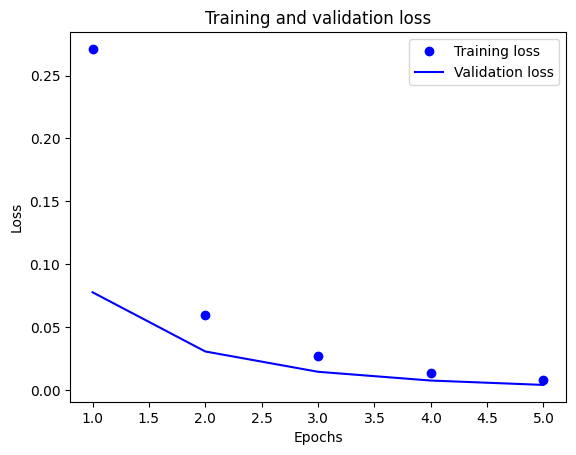

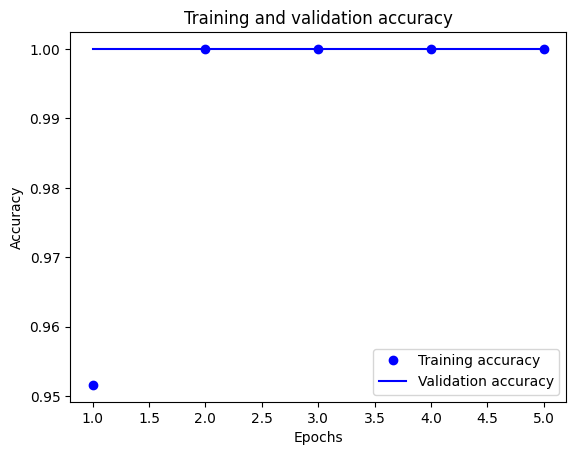

In [173]:
acc = history.history["accuracy"]
epochs = range(1, len(acc) + 1)

loss_values = history.history["loss"]
val_loss_values = history.history["val_loss"]

plt.plot(epochs, loss_values, "bo", label="Training loss")
plt.plot(epochs, val_loss_values, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.clf()

acc_values = history.history["accuracy"]
val_acc_values = history.history["val_accuracy"]

plt.plot(epochs, acc_values, "bo", label="Training accuracy")
plt.plot(epochs, val_acc_values, "b", label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [176]:
test_loss, test_acc = model.evaluate(X_test_vec, y_test_vec)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0045 


In [179]:
new_message = ["Congratulations! You've won a prize. Call now to claim it."]

new_message_seq = tokenizer.texts_to_sequences(new_message)
new_message_vec = vectorize_sequences(new_message_seq, 4000)

prediction = model.predict(new_message_vec)

if prediction[0] > 0.5:
    print("Predikcija: Spam")
else:
    print("Predikcija: Ham")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
Predikcija: Spam


# Zadatak 2

In [180]:
df = pd.read_csv("drive/MyDrive/Colab Notebooks/Vjestacka inteligencija/VI L4/stackoverflow.csv", sep=",")
df.tail(3)

,post,tags
1987,directory folder name to put user defined pack...,java
1988,send message to server java i m creating chat...,java
1989,how to add pattern of * is url-pattern in we...,java


In [181]:
X = df["post"]
y = df["tags"]

In [182]:
print(f"Broj jedinstvenih labela: {y.nunique()}")
print(f"Programski jezici: {y.unique()}")

Broj jedinstvenih labela: 4
Programski jezici: ['java' 'javascript' 'c#' 'python']


In [200]:
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

In [209]:
y_one_hot = to_categorical(y_encoded)

In [212]:
X_train, X_test, y_train_vec, y_test_vec = train_test_split(X, y_one_hot, test_size=0.1, random_state=42)
print(X_train.shape, X_test.shape, y_train_vec.shape, y_test_vec.shape)

(1791,) (199,) (1791, 4) (199, 4)


In [213]:
tokenizer = Tokenizer(num_words=500)
tokenizer.fit_on_texts(X_train)

In [214]:
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

In [215]:
def vectorize_sequences(sequences, dimension):
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.
    return results

In [216]:
X_train_vec = vectorize_sequences(X_train_seq, 500)
X_test_vec = vectorize_sequences(X_test_seq, 500)

In [217]:
model = models.Sequential()

model.add(layers.Input(shape=(500,)))
model.add(layers.Dense(32, activation='relu'))
model.add(layers.Dense(8, activation='relu'))
model.add(layers.Dense(len(y_train.unique()), activation='softmax'))

In [218]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 32)                  │          16,032 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 8)                   │             264 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 4)                   │              36 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 16,332 (63.80 KB)

 Trainable params: 16,332 (63.80 KB)

 Non-trainable params: 0 (0.00 B)

In [219]:
history = model.fit(X_train_vec, y_train_vec, epochs=8, batch_size=8, validation_split=0.25)

Epoch 1/8
168/168 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.4359 - loss: 1.2841 - val_accuracy: 0.8281 - val_loss: 0.6985
Epoch 2/8
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9013 - loss: 0.5082 - val_accuracy: 0.9308 - val_loss: 0.2971
Epoch 3/8
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9630 - loss: 0.1786 - val_accuracy: 0.9420 - val_loss: 0.2259
Epoch 4/8
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9806 - loss: 0.1041 - val_accuracy: 0.9375 - val_loss: 0.2064
Epoch 5/8
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9912 - loss: 0.0671 - val_accuracy: 0.9353 - val_loss: 0.1729
Epoch 6/8
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9992 - loss: 0.0420 - val_accuracy: 0.9397 - val_loss: 0.1786
Epoch 7/8
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9989 - loss: 0.0213 - val_accuracy: 0.9397 - val_loss: 0.1797
Epoch 8/8
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9997 - loss: 0.0176 - val_accuracy: 0.9353 - v

In [220]:
print(f"Finalna tačnost na trening setu: {history.history['accuracy'][-1]}")
print(f"Finalni gubitak na trening setu: {history.history['loss'][-1]}")
print(f"Finalna tačnost na validaciji: {history.history['val_accuracy'][-1]}")
print(f"Finalni gubitak na validaciji: {history.history['val_loss'][-1]}")

Finalna tačnost na trening setu: 0.9992554187774658
Finalni gubitak na trening setu: 0.01696339249610901
Finalna tačnost na validaciji: 0.9352678656578064
Finalni gubitak na validaciji: 0.1709652990102768


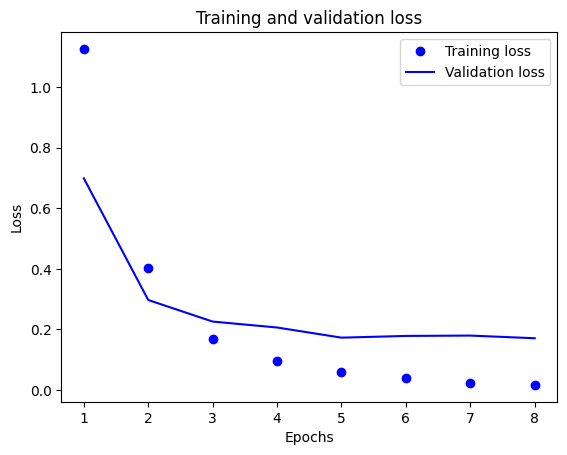

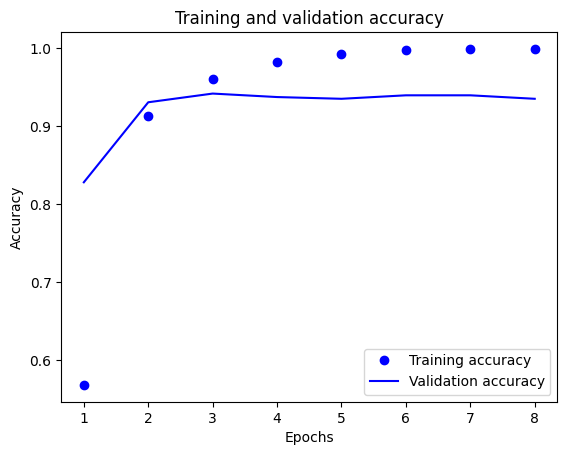

In [221]:
acc = history.history["accuracy"]
epochs = range(1, len(acc) + 1)

loss_values = history.history["loss"]
val_loss_values = history.history["val_loss"]

plt.plot(epochs, loss_values, "bo", label="Training loss")
plt.plot(epochs, val_loss_values, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.clf()

acc_values = history.history["accuracy"]
val_acc_values = history.history["val_accuracy"]

plt.plot(epochs, acc_values, "bo", label="Training accuracy")
plt.plot(epochs, val_acc_values, "b", label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [222]:
test_loss, test_acc = model.evaluate(X_test_vec, y_test_vec)

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.9235 - loss: 0.2640
